In [1]:
pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [3]:
df = pd.read_csv("/kaggle/input/datasets/atharvahjoshi/sales-dataset/sales_data_sample.xls" , encoding = "latin1")

print(df.head())


print( "\nLAST 10 ROWS Printing")
df.tail(10)


print("\nINFORMATION REGARDING THE DATASET DATA TYPES:")
print( df.info())

print("\nPRINT ATTRIBUTES NAMES : ")
print( df.columns)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [4]:
print( "  Number of rows and columns. :")
print(df.shape) 

print("   Checking for the empty values " )
print( df.isnull().sum())

  Number of rows and columns. :
(2823, 25)
   Checking for the empty values 
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64


[[-0.52289086  0.5969775  -0.37082523 -0.14224584]
 [-0.11220131 -0.11445035 -0.42789707 -0.14224584]
 [ 0.60650538  0.54938372  0.17944282 -0.14224584]
 ...
 [ 0.81185016  0.81015797  1.01202368 -1.16263387]
 [-0.11220131 -1.06186404 -0.78072155 -1.16263387]
 [ 1.2225397  -0.89925195 -0.25763729 -1.16263387]]


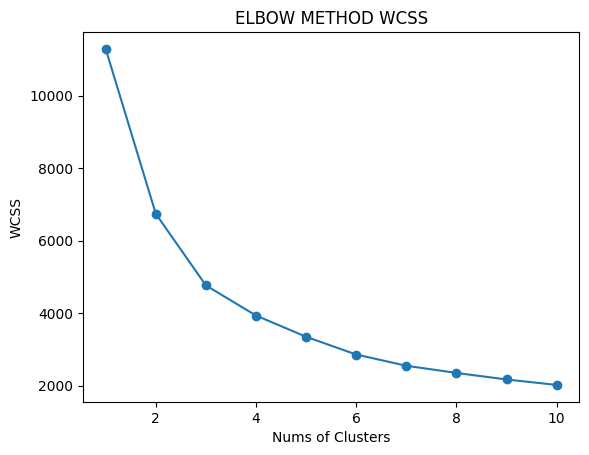

In [5]:
data = df[['QUANTITYORDERED', 'PRICEEACH','SALES' , 'MSRP']].dropna().copy()


# feature scaling
scaler = StandardScaler()
X = scaler.fit_transform(data)
print(X)

wcss = []
for i in range( 1 , 11):
    model = KMeans( n_clusters = i ,
                   random_state = 42,
                   n_init = 10
                  )
    model.fit(X)
    wcss.append( model.inertia_ )


plt.plot( range(1, 11) , wcss , marker='o')
plt.xlabel("Nums of Clusters")
plt.ylabel("WCSS")
plt.title("ELBOW METHOD WCSS")
plt.show()


In [6]:
# 6. Apply K-Means (Optimal K = 3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X)

# 7. Display Results
print("\nCluster Counts:")
print(data['Cluster'].value_counts().sort_index())

print("\nCluster Mean:")
print(data.groupby('Cluster').mean())


Cluster Counts:
Cluster
0    975
1    852
2    996
Name: count, dtype: int64

Cluster Mean:
         QUANTITYORDERED  PRICEEACH        SALES        MSRP
Cluster                                                     
0              35.208205  59.551169  2101.076482   64.145641
1              43.723005  97.479261  5720.080669  127.893192
2              27.597390  95.435090  3123.062801  113.266064


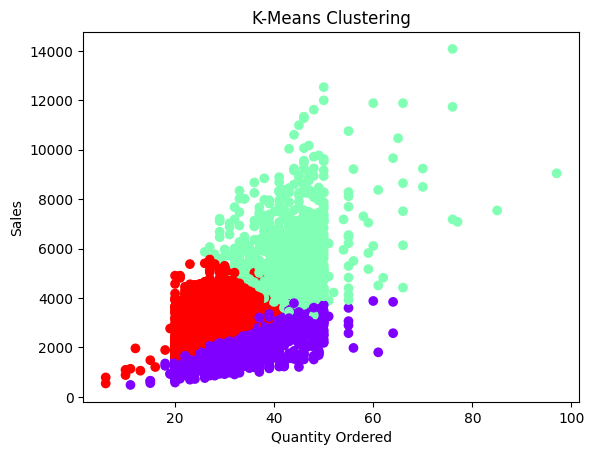


Clustering Completed Successfully!


In [7]:


# 8. Visualize Clusters
plt.scatter(data['QUANTITYORDERED'], data['SALES'],
            c=data['Cluster'], cmap='rainbow')

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering")
plt.show()

# 9. Save Result
data.to_csv("clustered_sales.csv", index=False)

print("\nClustering Completed Successfully!")


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load dataset
df = pd.read_csv("sales_data_sample.csv", encoding='latin1')

# 2. Select features and remove missing values
df = df.dropna(subset=['QUANTITYORDERED', 'SALES'])

X = df[['QUANTITYORDERED', 'SALES']]

# 3. Normalize data
sc = StandardScaler()
X = sc.fit_transform(X)

# 4. Elbow Method
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

# 5. Plot elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 6. Apply K-Means
km = KMeans(n_clusters=3, random_state=42, n_init=10)
y = km.fit_predict(X)

print("Cluster Labels:")
print(y)

# 7. Plot clusters
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Quantity Ordered (Scaled)")
plt.ylabel("Sales (Scaled)")
plt.title("K-Means Clustering")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'sales_data_sample.csv'